<a href="https://colab.research.google.com/github/ChronosXV/Metodologia_grupo2/blob/noelia_modelado/Metodologia_1_Grupo_2_Modelado_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Trabajo Práctico Final

**Materia:**

Metodología de la Investigación

**Alumnos:**

- Gisela Martínez
- Noelia Cualina
- José Leonardo Carabajal
- Javier Carabajal


**Objetivo:**

Desarrollar y evaluar modelos de Machine Learning para predecir niveles de demanda en la red de subtes de CABA.

Período de estudio: 2017–2021.



Enfoque: cuantitativo, descriptivo y predictivo.



Metodología: CRISP-DM.



Variable objetivo: nivel_demanda, con categorías baja, media y alta.



Variable base para construir el objetivo: pax_total.



Variables predictoras: línea, estación, franja horaria, año, mes, día de la semana y condición de día hábil.



Evaluación: accuracy, precision, recall, F1-score y matriz de confusión.

### 1. Introducción y objetivo del modelado

El presente trabajo constituye la continuación del análisis exploratorio y la preparación de datos realizados sobre los registros históricos de pasajeros de la red de subterráneos de la Ciudad Autónoma de Buenos Aires durante el período 2017–2021.

En esta etapa se propone desarrollar y evaluar modelos de Machine Learning que permitan clasificar y predecir niveles de demanda de pasajeros, utilizando información temporal y espacial disponible en los registros históricos.

Para ello, se utilizará el conjunto de datos previamente procesado y agrupado por fecha, línea, estación y franja horaria, tomando como referencia la cantidad total de pasajeros registrados (pax_total).

A partir de esta variable se construirán tres categorías de demanda: baja, media y alta, que constituirán la variable objetivo (nivel_demanda) del problema de clasificación supervisada.

Los modelos utilizarán características como la línea, la estación, la franja horaria y variables temporales derivadas de la fecha. La cantidad total de pasajeros no será incorporada como variable predictora, dado que se utilizará para construir la variable objetivo.

Se compararán distintos algoritmos de clasificación mediante métricas de evaluación apropiadas, prestando especial atención a la identificación de situaciones de alta demanda.

Asimismo, se contempla la aplicación de técnicas de aprendizaje no supervisado como análisis complementario, con el propósito de identificar posibles agrupamientos en los patrones de demanda.

El desarrollo seguirá las etapas de modelado y evaluación de la metodología CRISP-DM, buscando obtener resultados reproducibles que permitan contrastar la hipótesis planteada y formular recomendaciones basadas en evidencia cuantitativa.
####

**Hipótesis de investigación**

Los episodios de alta demanda en la red de subtes de CABA durante el período 2017–2021 no se distribuyen de manera uniforme, sino que presentan patrones asociados a factores temporales y espaciales. Se espera que la probabilidad de registrar niveles elevados de demanda varíe según la estación, la línea, el día de la semana y la franja horaria, permitiendo identificar y predecir situaciones de alta demanda a partir de estas características.


### 2. Importación de librerías y carga del dataset procesado.

En esta sección se importan las bibliotecas necesarias para el procesamiento de datos, la construcción de modelos de Machine Learning y la evaluación de resultados. Posteriormente, se carga el conjunto de datos consolidado durante la etapa de preparación, que servirá como base para el modelado predictivo.

In [18]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np
import os

# Visualización de resultados
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import recall_score

# Modelos de clasificación supervisada
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluación de modelos
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Aprendizaje no supervisado
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Acceso a Google Drive
from google.colab import drive

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# Montar Google Drive
drive.mount("/content/drive")

# Definir la ruta del dataset procesado
ruta_carpeta = "/content/drive/MyDrive/Datos_csv/"
ruta_limpios = os.path.join(ruta_carpeta, "datos_limpios")

ruta_dataset = os.path.join(
    ruta_limpios,
    "historico_2017_2021_dim.parquet"
)

# Cargar el dataset consolidado
df = pd.read_parquet(ruta_dataset)

# Verificar la carga
print("Dataset cargado correctamente.")
print(f"Cantidad de registros: {df.shape[0]:,}")
print(f"Cantidad de columnas: {df.shape[1]}")

Mounted at /content/drive
Dataset cargado correctamente.
Cantidad de registros: 653,619
Cantidad de columnas: 6


In [3]:
display(df.head())

,fecha,linea,estacion,franja_horaria_num,franja_horaria,pax_total
0,2017-11-27,D,9 DE JULIO,5,Noche,535.0
1,2017-11-28,D,9 DE JULIO,1,Madrugada,9.0
2,2017-11-28,D,9 DE JULIO,2,Pico mañana,1922.0
3,2017-11-28,D,9 DE JULIO,3,Media mañana,4345.0
4,2017-11-29,D,9 DE JULIO,2,Pico mañana,1722.0


In [4]:
# Verificar estructura y tipos de datos del dataset
print("Información general del dataset:")
df.info()

print("\nValores nulos por columna:")
print(df.isnull().sum())

Información general del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 653619 entries, 0 to 653618
Data columns (total 6 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   fecha               653619 non-null  object 
 1   linea               653619 non-null  object 
 2   estacion            653619 non-null  object 
 3   franja_horaria_num  653619 non-null  int32  
 4   franja_horaria      653619 non-null  object 
 5   pax_total           653619 non-null  float64
dtypes: float64(1), int32(1), object(4)
memory usage: 27.4+ MB

Valores nulos por columna:
fecha                 0
linea                 0
estacion              0
franja_horaria_num    0
franja_horaria        0
pax_total             0
dtype: int64


### 3. Construcción de variables predictoras.

En esta etapa se preparan las variables que serán utilizadas como características de entrada para los modelos de Machine Learning.

A partir del conjunto de datos consolidado, se conservarán las variables espaciales y temporales disponibles, como la línea, la estación y la franja horaria. Además, se construirán nuevas variables a partir de la fecha, con el propósito de representar patrones asociados al comportamiento de la demanda de pasajeros.

Las variables derivadas serán:

*  Año: permite identificar variaciones de demanda entre los distintos años del período analizado.
*  Mes: permite representar posibles patrones estacionales.
*  Día de la semana: permite identificar diferencias de demanda entre lunes y domingo.
*  Fin de semana: permite distinguir sábados y domingos del resto de los días.


La variable pax_total se conservará únicamente para la posterior construcción de la variable objetivo nivel_demanda, correspondiente a las categorías baja, media y alta.

De esta manera, se busca que los modelos aprendan relaciones entre las características temporales y espaciales y los niveles de demanda, evitando incorporar directamente como predictor la cantidad de pasajeros que se desea clasificar.

In [5]:
# Crear una copia del dataset para el modelado
df_modelo = df.copy()

# Convertir la columna fecha a tipo datetime
df_modelo["fecha"] = pd.to_datetime(
    df_modelo["fecha"],
    format="%Y-%m-%d",
    errors="raise"
)

# Construir variables temporales
df_modelo["anio"] = df_modelo["fecha"].dt.year
df_modelo["mes"] = df_modelo["fecha"].dt.month
df_modelo["dia_semana"] = df_modelo["fecha"].dt.dayofweek

# Identificar fines de semana: sábado (5) y domingo (6)
df_modelo["fin_semana"] = (
    df_modelo["dia_semana"] >= 5
).astype(int)

# Visualizar los primeros registros
display(df_modelo.head())

print("\nDimensiones del dataset:", df_modelo.shape)

,fecha,linea,estacion,franja_horaria_num,franja_horaria,pax_total,anio,mes,dia_semana,fin_semana
0,2017-11-27,D,9 DE JULIO,5,Noche,535.0,2017,11,0,0
1,2017-11-28,D,9 DE JULIO,1,Madrugada,9.0,2017,11,1,0
2,2017-11-28,D,9 DE JULIO,2,Pico mañana,1922.0,2017,11,1,0
3,2017-11-28,D,9 DE JULIO,3,Media mañana,4345.0,2017,11,1,0
4,2017-11-29,D,9 DE JULIO,2,Pico mañana,1722.0,2017,11,2,0



Dimensiones del dataset: (653619, 10)


In [6]:
# Seleccionar las variables predictoras
variables_predictoras = [
    "linea",
    "estacion",
    "franja_horaria_num",
    "anio",
    "mes",
    "dia_semana"
]

# Crear el conjunto de características
X = df_modelo[variables_predictoras].copy()

# Verificar las variables seleccionadas
print("Variables predictoras:")
print(X.columns.tolist())

print("\nDimensiones de X:", X.shape)

display(X.head())

Variables predictoras:
['linea', 'estacion', 'franja_horaria_num', 'anio', 'mes', 'dia_semana']

Dimensiones de X: (653619, 6)


,linea,estacion,franja_horaria_num,anio,mes,dia_semana
0,D,9 DE JULIO,5,2017,11,0
1,D,9 DE JULIO,1,2017,11,1
2,D,9 DE JULIO,2,2017,11,1
3,D,9 DE JULIO,3,2017,11,1
4,D,9 DE JULIO,2,2017,11,2


### 4. Definición de la variable objetivo nivel_demanda.

Para el desarrollo de los modelos de clasificación supervisada, se construirá una variable objetivo denominada nivel_demanda, que permitirá clasificar los registros históricos de pasajeros en tres categorías: baja, media y alta demanda.

Esta clasificación se realizará a partir de la variable pax_total, que representa la cantidad total de pasajeros registrada para cada combinación de fecha, línea, estación y franja horaria.

Se propone utilizar un criterio basado en cuantiles, dividiendo la distribución de pasajeros en tres grupos mediante los percentiles 33,33 y 66,67. Este procedimiento permitirá establecer umbrales reproducibles a partir de la distribución observada.

Para evitar fugas de información, los umbrales definitivos se calcularán exclusivamente sobre el conjunto de entrenamiento, después de realizar la separación temporal de los datos. Posteriormente, se aplicarán los mismos límites al conjunto de prueba.

La variable pax_total no se utilizará como característica predictora, ya que constituye la información a partir de la cual se define la variable objetivo.

Es importante señalar que los niveles establecidos representan categorías relativas de demanda de pasajeros, utilizadas como aproximación para identificar situaciones potenciales de congestión, y no mediciones directas de ocupación o saturación de las estaciones.

In [7]:
# Separación temporal preliminar del dataset
# Entrenamiento: 2017 a 2020
# Prueba: 2021

df_train = df_modelo[
    df_modelo["anio"] <= 2020
].copy()

df_test = df_modelo[
    df_modelo["anio"] == 2021
].copy()

# Verificar la cantidad de registros
print("Registros de entrenamiento:", len(df_train))
print("Registros de prueba:", len(df_test))

print("\nDistribución porcentual:")
print(
    f"Entrenamiento: {len(df_train) / len(df_modelo) * 100:.2f}%"
)

Registros de entrenamiento: 541247
Registros de prueba: 112372

Distribución porcentual:
Entrenamiento: 82.81%


In [8]:
# Calcular los cuantiles únicamente con datos de entrenamiento
cuantiles = df_train["pax_total"].quantile([1/3, 2/3])

# Mostrar los valores obtenidos
print("Cuantiles de pax_total (2017-2020):")
print(cuantiles)

Cuantiles de pax_total (2017-2020):
0.333333     354.0
0.666667    1825.0
Name: pax_total, dtype: float64


**Interpretación de los cuantiles obtenidos**

A partir de los registros correspondientes al conjunto de entrenamiento (2017–2020), se calcularon los percentiles 33,33 y 66,67 de la variable `pax_total`, obteniendo los siguientes resultados:

| Percentil | Pasajeros | Interpretación |
|---|---:|---|
| 33,33 % | 354 | Límite entre demanda baja y media |
| 66,67 % | 1.825 | Límite entre demanda media y alta |

Estos valores permiten establecer tres niveles de demanda:

- **Demanda baja:** registros con hasta 354 pasajeros.
- **Demanda media:** registros con más de 354 y hasta 1.825 pasajeros.
- **Demanda alta:** registros con más de 1.825 pasajeros.

Los umbrales se definieron utilizando exclusivamente los datos de entrenamiento y se aplicarán posteriormente al conjunto de prueba (2021), manteniendo el mismo criterio de clasificación.

Es importante destacar que estas categorías representan niveles relativos de demanda según la distribución histórica de pasajeros, y no umbrales operativos de congestión establecidos por la capacidad de las estaciones.

In [9]:
# Obtener los umbrales calculados con entrenamiento
umbral_bajo = cuantiles.loc[1/3]
umbral_alto = cuantiles.loc[2/3]

# Función para clasificar la demanda de pasajeros
def clasificar_demanda(pasajeros):
    """
    Clasifica la cantidad de pasajeros en tres niveles de demanda:
    Baja, Media o Alta.

    Utiliza los umbrales calculados a partir de los cuantiles
    33,33 % y 66,67 % del conjunto de entrenamiento (2017-2020).

    Parámetros:
        pasajeros: cantidad total de pasajeros del registro.

    Retorna:
        str: categoría de demanda correspondiente.
    """
    if pasajeros <= umbral_bajo:
        return "Baja"
    elif pasajeros <= umbral_alto:
        return "Media"
    else:
        return "Alta"

# Aplicar los mismos umbrales a entrenamiento y prueba
df_train["nivel_demanda"] = (
    df_train["pax_total"].apply(clasificar_demanda)
)

df_test["nivel_demanda"] = (
    df_test["pax_total"].apply(clasificar_demanda)
)

# Verificar la distribución de las categorías
print("Distribución de demanda - Entrenamiento:")
print(df_train["nivel_demanda"].value_counts())

print("\nDistribución de demanda - Prueba:")
print(df_test["nivel_demanda"].value_counts())

Distribución de demanda - Entrenamiento:
nivel_demanda
Media    180453
Baja     180441
Alta     180353
Name: count, dtype: int64

Distribución de demanda - Prueba:
nivel_demanda
Baja     54101
Media    42326
Alta     15945
Name: count, dtype: int64


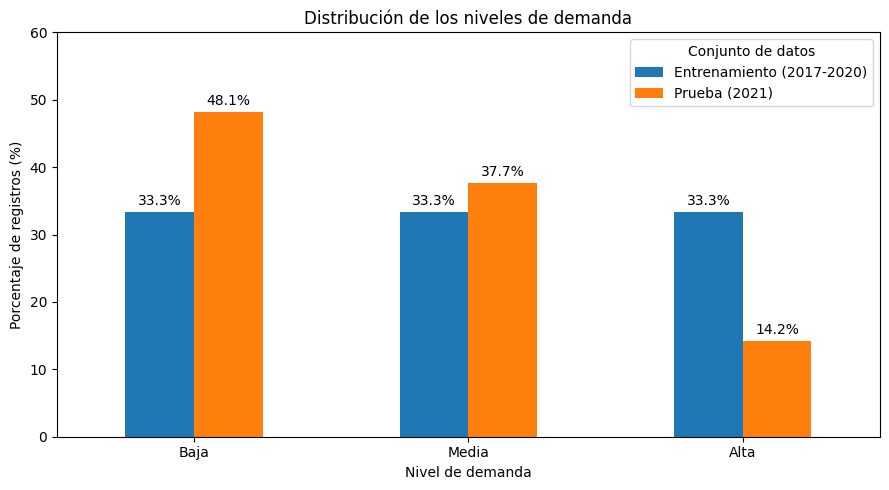

In [10]:
# Comparar la distribución porcentual de los niveles de demanda
orden_niveles = ["Baja", "Media", "Alta"]

# Calcular porcentajes por conjunto
porcentaje_train = (
    df_train["nivel_demanda"]
    .value_counts(normalize=True)
    .reindex(orden_niveles)
    .mul(100)
)

porcentaje_test = (
    df_test["nivel_demanda"]
    .value_counts(normalize=True)
    .reindex(orden_niveles)
    .mul(100)
)

# Preparar los datos para el gráfico
df_distribucion = pd.DataFrame({
    "Entrenamiento (2017-2020)": porcentaje_train,
    "Prueba (2021)": porcentaje_test
})

# Visualizar la comparación
ax = df_distribucion.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Distribución de los niveles de demanda")
ax.set_xlabel("Nivel de demanda")
ax.set_ylabel("Porcentaje de registros (%)")
ax.legend(title="Conjunto de datos")

# Mostrar porcentajes sobre cada barra
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f%%", padding=3)

plt.ylim(0, 60)
plt.tight_layout()
plt.show()


**Interpretación de la distribución de los niveles de demanda**

A partir de los umbrales definidos mediante los cuantiles del conjunto de entrenamiento, se construyó la variable objetivo nivel_demanda, clasificando los registros en tres categorías: baja, media y alta.

En el conjunto de entrenamiento (2017–2020), las categorías presentan una distribución prácticamente equilibrada, con aproximadamente un tercio de los registros en cada nivel. Este resultado es consistente con el criterio de clasificación basado en terciles.

En cambio, en el conjunto de prueba (2021), se observa una distribución diferente: **el 48,1 % de los registros corresponde a demanda baja**, **el 37,7 % a demanda media** y solamente **el 14,2 % a demanda alta**.

Esta diferencia evidencia un cambio en la distribución relativa de los niveles de demanda entre ambos períodos, utilizando los mismos umbrales de clasificación. Si bien podría estar relacionada con las modificaciones en la movilidad urbana durante la pandemia de COVID-19, los resultados obtenidos no permiten establecer por sí solos una relación causal.

Estos hallazgos serán considerados posteriormente durante la evaluación de los modelos predictivos, especialmente al analizar su capacidad para identificar correctamente los registros de alta demanda.

### 5. Preparación de datos y separación temporal.

####5.1 Preparación de datos para el entrenamiento

En esta etapa se preparan los conjuntos de datos que serán utilizados para entrenar y evaluar los modelos de clasificación supervisada.

Se mantiene la separación temporal definida anteriormente, utilizando los registros de **2017–2020 para entrenamiento** y los correspondientes a **2021 para prueba**. Este criterio permite evaluar la capacidad de los modelos para clasificar registros de un período posterior al utilizado durante el aprendizaje.

Las variables predictoras se agruparán en una matriz de características (`X`), mientras que la variable objetivo `nivel_demanda` se almacenará por separado (`y`).

Debido a que algunas características, como la línea y la estación, son categóricas, será necesario aplicar técnicas de codificación para convertirlas en representaciones compatibles con los algoritmos de Machine Learning.

Estas transformaciones se ajustarán exclusivamente con los datos de entrenamiento y se aplicarán posteriormente al conjunto de prueba, evitando fugas de información.

La variable `pax_total` no será incorporada como predictor, dado que fue utilizada para definir los niveles de demanda.

####5.2 Separar características predictoras y variable objetivo

In [11]:
# Conjunto de entrenamiento (2017-2020)
X_train = df_train[variables_predictoras].copy()
y_train = df_train["nivel_demanda"].copy()

# Conjunto de prueba (2021)
X_test = df_test[variables_predictoras].copy()
y_test = df_test["nivel_demanda"].copy()

# Verificar las dimensiones
print("Entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPrueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Verificar las categorías de la variable objetivo
print("\nCategorías de demanda:")
print(y_train.unique())

Entrenamiento:
X_train: (541247, 6)
y_train: (541247,)

Prueba:
X_test: (112372, 6)
y_test: (112372,)

Categorías de demanda:
['Media' 'Baja' 'Alta']


#### 5.3 Codificación y transformación de variables predictoras

Antes de entrenar los modelos de Machine Learning, es necesario preparar las variables predictoras para que puedan ser procesadas correctamente por los algoritmos.

En nuestro conjunto de datos contamos con variables categóricas, como la línea y la estación de subte, y variables temporales, como el año, mes, día de la semana y franja horaria.

Para realizar estas transformaciones se utilizarán las siguientes técnicas:

* **One-Hot Encoding:** permite transformar las variables categóricas en columnas binarias (0 y 1), evitando que los algoritmos interpreten sus categorías como valores numéricos ordenados. Se aplicará a linea, estacion, franja_horaria_num, mes y dia_semana.

* **StandardScaler:** permite estandarizar la variable numérica anio, ajustando sus valores a una escala basada en la media y la desviación estándar del conjunto de entrenamiento.

* **ColumnTransformer:** permite combinar ambas transformaciones y aplicarlas a las columnas correspondientes dentro de un mismo proceso de preprocesamiento.

Se utilizará el parámetro handle_unknown="ignore" en OneHotEncoder para permitir que el modelo procese categorías no observadas durante el entrenamiento.

El preprocesador se integrará posteriormente en un Pipeline, de manera que las transformaciones se ajusten exclusivamente con los datos de entrenamiento (2017–2020) y se apliquen al conjunto de prueba (2021), evitando fugas de información.

Este procedimiento permitirá mantener un proceso de preparación de datos consistente y reproducible para los diferentes modelos de clasificación.

In [12]:
# Definir las variables categóricas y numéricas
variables_categoricas = [
    "linea",
    "estacion",
    "franja_horaria_num",
    "mes",
    "dia_semana"
]

variables_numericas = ["anio"]

# Crear el transformador de variables
preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        )
    ]
)

print("Preprocesador definido correctamente.")
print("\nVariables categóricas:", variables_categoricas)
print("Variables numéricas:", variables_numericas)


Preprocesador definido correctamente.

Variables categóricas: ['linea', 'estacion', 'franja_horaria_num', 'mes', 'dia_semana']
Variables numéricas: ['anio']


#### 5.4 Construcción del Pipeline

Para organizar el proceso de entrenamiento se utilizará la clase Pipeline de Scikit-learn, que permite integrar las etapas de preprocesamiento y modelado dentro de un mismo flujo de trabajo.

En este caso, el Pipeline estará compuesto por dos etapas:

* **Preprocesamiento:** aplica las transformaciones definidas mediante ColumnTransformer, incluyendo la codificación de variables categóricas con OneHotEncoder y la estandarización de la variable numérica anio con StandardScaler.

* **Clasificación**: utiliza un algoritmo de Machine Learning para aprender la relación entre las variables predictoras y los niveles de demanda de pasajeros.

Como primer modelo se utilizará **Regresión Logística**, un algoritmo de clasificación supervisada que permite predecir la pertenencia de cada registro a una de las tres categorías de demanda: baja, media o alta.

La utilización de un Pipeline permite que las transformaciones se ajusten únicamente con los datos de entrenamiento y se apliquen posteriormente de manera consistente al conjunto de prueba, reduciendo el riesgo de fugas de información.

En esta instancia se definirá la estructura del Pipeline, mientras que el entrenamiento y la evaluación del modelo se realizarán en las siguientes etapas.

In [13]:

# Construir el Pipeline para Regresión Logística
pipeline_logistica = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

# Verificar la estructura del Pipeline
print("Pipeline de Regresión Logística definido correctamente.")
print("\nEtapas del Pipeline:")
print(pipeline_logistica.named_steps.keys())

# Visualizar el Pipeline
display(pipeline_logistica)

Pipeline de Regresión Logística definido correctamente.

Etapas del Pipeline:
dict_keys(['preprocesamiento', 'clasificador'])


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['linea', 'estacion',
                                                   'franja_horaria_num', 'mes',
                                                   'dia_semana']),
                                                 ('numericas', StandardScaler(),
                                                  ['anio'])])),
                ('clasificador',
                 LogisticRegression(max_iter=1000, random_state=42))])

**Aclaraciones sobre la configuración del Pipeline**

En la construcción del Pipeline se utilizaron algunos parámetros y métodos que permiten configurar el algoritmo y verificar su estructura:

* **max_iter=1000:** establece un máximo de 1.000 iteraciones para que el algoritmo de Regresión Logística intente alcanzar la convergencia durante el entrenamiento.

* **random_state=42:** establece una semilla para favorecer la reproducibilidad de los resultados en aquellos procesos que involucren aleatoriedad.

* **named_steps:** permite consultar las etapas que componen el Pipeline y acceder a sus componentes mediante los nombres definidos.

La visualización obtenida confirma que el Pipeline integra correctamente el preprocesamiento de las variables categóricas y numéricas con el clasificador de Regresión Logística.

En esta instancia, el Pipeline se encuentra definido, pero todavía no entrenado. El ajuste del modelo se realizará posteriormente utilizando los datos correspondientes al conjunto de entrenamiento.

###6. Entrenamiento de modelos supervisados.

#### 6.1 Explicación metodológica

En esta etapa se desarrollarán modelos de clasificación supervisada para predecir los niveles de demanda de pasajeros en la red de subtes de la Ciudad Autónoma de Buenos Aires.

Para el entrenamiento se utilizarán los registros correspondientes al período 2017–2020, mientras que los datos de 2021 se mantendrán reservados para la evaluación posterior.

Se implementarán dos algoritmos de clasificación:

*  **Regresión Logística:** modelo estadístico utilizado para problemas de clasificación que permite estimar la probabilidad de pertenencia a diferentes categorías. En este trabajo se utilizará como modelo de referencia para la clasificación multiclase de los niveles de demanda.
*  **Random Forest:** algoritmo basado en un conjunto de árboles de decisión que permite identificar relaciones no lineales e interacciones entre las variables predictoras.

Ambos modelos utilizarán las mismas características de entrada y la variable objetivo **nivel_demanda**, permitiendo comparar posteriormente su desempeño mediante métricas de clasificación.

El entrenamiento se realizará mediante Pipelines de Scikit-learn, integrando las transformaciones de las variables con los respectivos algoritmos.

Esta estrategia busca mantener un procedimiento reproducible y evitar fugas de información entre los conjuntos de entrenamiento y prueba.

#### 6.2 Entrenamiento del primer modelo: Regresión Logística

La instrucción fit(X_train, y_train) realiza dos tareas:

1. Ajusta el preprocesamiento: aprende las categorías necesarias para OneHotEncoder y los parámetros de escalado de StandardScaler utilizando solamente los datos de entrenamiento.
2. Entrena la Regresión Logística: aprende la relación entre las variables predictoras y las categorías de demanda.

In [14]:
# Entrenar el modelo de Regresión Logística
print("Iniciando entrenamiento de Regresión Logística...")

pipeline_logistica.fit(X_train, y_train)

print("Entrenamiento de Regresión Logística finalizado correctamente.")

Iniciando entrenamiento de Regresión Logística...
Entrenamiento de Regresión Logística finalizado correctamente.


#### 6.3 Entrenamiento del segundo modelo: Random Forest

Como segundo algoritmo de clasificación supervisada se utilizará Random Forest, un método de aprendizaje basado en conjuntos de árboles de decisión.

Este algoritmo combina las predicciones de múltiples árboles para determinar la categoría final de cada registro. A diferencia de la Regresión Logística, permite identificar relaciones no lineales e interacciones entre las variables predictoras.

Para mantener la consistencia metodológica, se utilizarán los mismos conjuntos de entrenamiento y prueba, así como las mismas variables predictoras definidas anteriormente.

El modelo se integrará en un Pipeline que incluirá el preprocesamiento de los datos y el clasificador Random Forest.

Posteriormente, ambos algoritmos serán evaluados utilizando las mismas métricas, con el propósito de comparar su capacidad para identificar los niveles de demanda baja, media y alta.

In [15]:
# Construir el Pipeline para Random Forest
pipeline_rf = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=15,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Entrenar el modelo
print("Iniciando entrenamiento de Random Forest...")

pipeline_rf.fit(X_train, y_train)

print("Entrenamiento de Random Forest finalizado correctamente.")

Iniciando entrenamiento de Random Forest...
Entrenamiento de Random Forest finalizado correctamente.


#### 6.4 Resultado del entrenamiento

Se completó correctamente el entrenamiento de los dos modelos de clasificación supervisada propuestos: Regresión Logística y Random Forest.

Ambos algoritmos fueron ajustados utilizando los registros históricos correspondientes al período 2017–2020, manteniendo los datos de 2021 reservados para la evaluación.

La ejecución de los respectivos Pipelines finalizó sin errores, permitiendo avanzar hacia la etapa de predicción y evaluación de resultados.

En la siguiente sección se analizará el desempeño de ambos modelos mediante métricas de clasificación y matrices de confusión, prestando especial atención a su capacidad para identificar registros correspondientes a niveles de demanda alta.

###7. Evaluación y comparación de resultados.

#### 7.1 Explicación metodológica

En esta etapa se evaluará el desempeño de los modelos de clasificación supervisada entrenados previamente: Regresión Logística y Random Forest.

Para ello, se utilizará el conjunto de prueba correspondiente al año 2021, compuesto por 112.372 registros que no fueron utilizados durante el entrenamiento.

Cada modelo generará predicciones de la variable objetivo nivel_demanda, clasificando los registros en tres categorías: baja, media y alta demanda.

Las predicciones obtenidas se compararán con las categorías reales del conjunto de prueba mediante las siguientes métricas:

*  **Accuracy (exactitud):** proporción de registros clasificados correctamente respecto del total.

*  **Precision (precisión):** proporción de predicciones correctas entre todos los registros que el modelo asignó a una determinada categoría.

*  **Recall (sensibilidad):** proporción de registros reales de una categoría que el modelo logró identificar correctamente.

*  **F1-score:** medida que combina precision y recall, permitiendo evaluar el equilibrio entre ambas métricas.

*  **Matriz de confusión:** permite identificar los aciertos y errores de clasificación para cada nivel de demanda.

Se prestará especial atención al desempeño sobre la categoría Alta, debido a su relevancia para el objetivo de identificar situaciones de elevada demanda de pasajeros.

La comparación permitirá determinar cuál de los algoritmos presenta un mejor desempeño sobre los datos de prueba y analizar sus principales limitaciones.

Dado que la distribución de categorías en 2021 difiere de la observada durante el entrenamiento, también se considerarán métricas por categoría y promedios macro, evitando basar las conclusiones únicamente en la exactitud global.

#### 7.2 Generación de predicciones

In [16]:
# Generar predicciones sobre el conjunto de prueba (2021)

# Predicciones de Regresión Logística
y_pred_logistica = pipeline_logistica.predict(X_test)

# Predicciones de Random Forest
y_pred_rf = pipeline_rf.predict(X_test)

# Verificar la cantidad de predicciones
print("Predicciones de Regresión Logística:", len(y_pred_logistica))
print("Predicciones de Random Forest:", len(y_pred_rf))

# Visualizar algunos resultados
df_predicciones = pd.DataFrame({
    "Nivel real": y_test.to_numpy(),
    "Regresión Logística": y_pred_logistica,
    "Random Forest": y_pred_rf
})

display(df_predicciones.head(10))

Predicciones de Regresión Logística: 112372
Predicciones de Random Forest: 112372


,Nivel real,Regresión Logística,Random Forest
0,Baja,Media,Alta
1,Baja,Media,Alta
2,Baja,Media,Alta
3,Baja,Alta,Alta
4,Baja,Baja,Alta
5,Baja,Alta,Media
6,Baja,Baja,Media
7,Baja,Baja,Media
8,Baja,Media,Alta
9,Baja,Media,Alta


**Interpretación de los resultados**

Mediante el método .predict(X_test), cada Pipeline aplica las transformaciones aprendidas durante el entrenamiento y genera una predicción del nivel de demanda para cada registro del conjunto de prueba correspondiente a 2021.

Ambos modelos generaron correctamente 112.372 predicciones, coincidiendo con la cantidad de registros del conjunto de prueba.

El DataFrame df_predicciones permite comparar el nivel de demanda real con las categorías estimadas por Regresión Logística y Random Forest.

En los primeros registros visualizados se observan diferencias entre las predicciones de ambos modelos y algunos errores de clasificación. Sin embargo, esta muestra inicial no es suficiente para determinar cuál presenta un mejor desempeño.

Para obtener una evaluación más completa, en la siguiente etapa se calcularán métricas de clasificación sobre la totalidad del conjunto de prueba.

#### 7.3 Evaluación mediante métricas de clasificación

Una vez generadas las predicciones sobre el conjunto de prueba, se evaluará el desempeño de los modelos de Regresión Logística y Random Forest mediante diferentes métricas de clasificación.

Se utilizarán las siguientes métricas:

*  **Accuracy:** indica la proporción total de predicciones correctas.

*  **Precision:** mide qué proporción de los registros clasificados en una categoría pertenece realmente a ella.

*  **Recall:** indica qué proporción de los registros reales de una categoría fue identificada correctamente.

*  **F1-score:** combina precision y recall para proporcionar una medida equilibrada del desempeño.

Además, se utilizará el classification report de Scikit-learn, que presenta estas métricas para cada una de las categorías de demanda: Baja, Media y Alta.

Se analizarán también los promedios *macro avg* y *weighted avg*. El primero otorga la misma importancia a las tres categorías, mientras que el segundo considera la cantidad de registros de cada una.

Dado que la distribución de los niveles de demanda en 2021 no es equilibrada, se prestará especial atención al **F1-score macro** y al **recall de la categoría Alta**, además de la exactitud global.

Esto permitirá comparar ambos algoritmos e identificar posibles dificultades para reconocer determinados niveles de demanda.

In [17]:

# Evaluación de los modelos sobre el conjunto de prueba (2021)

orden_niveles = ["Baja", "Media", "Alta"]

# Regresión Logística
print("=== REGRESIÓN LOGÍSTICA ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_logistica):.4f}")
print(f"F1-score macro: {f1_score(y_test, y_pred_logistica, average='macro'):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_logistica,
    labels=orden_niveles,
    zero_division=0
))

# Random Forest
print("\n=== RANDOM FOREST ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"F1-score macro: {f1_score(y_test, y_pred_rf, average='macro'):.4f}")

print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=orden_niveles,
    zero_division=0
))

=== REGRESIÓN LOGÍSTICA ===
Accuracy: 0.6745
F1-score macro: 0.6277

Reporte de clasificación:
              precision    recall  f1-score   support

        Baja       0.70      0.93      0.80     54101
       Media       0.69      0.34      0.45     42326
        Alta       0.58      0.69      0.63     15945

    accuracy                           0.67    112372
   macro avg       0.65      0.65      0.63    112372
weighted avg       0.68      0.67      0.64    112372


=== RANDOM FOREST ===
Accuracy: 0.5684
F1-score macro: 0.4631

Reporte de clasificación:
              precision    recall  f1-score   support

        Baja       0.65      0.87      0.74     54101
       Media       0.45      0.31      0.37     42326
        Alta       0.35      0.23      0.28     15945

    accuracy                           0.57    112372
   macro avg       0.48      0.47      0.46    112372
weighted avg       0.53      0.57      0.54    112372



**Comparación de resultados entre modelos**

La siguiente tabla resume las principales métricas obtenidas por los modelos de Regresión Logística y Random Forest sobre el conjunto de prueba correspondiente a 2021.

| Métrica | Regresión Logística | Random Forest |
|---|---:|---:|
| Accuracy | **67,45 %** | 56,84 % |
| F1-score macro | **0,6277** | 0,4631 |
| Recall demanda Baja | **0,93** | 0,87 |
| Recall demanda Media | **0,34** | 0,31 |
| Recall demanda Alta | **0,69** | 0,23 |
| F1-score demanda Alta | **0,63** | 0,28 |

Los resultados muestran que la Regresión Logística supera a Random Forest en todas las métricas seleccionadas. La diferencia más significativa se observa en el recall de la categoría Alta, donde la Regresión Logística alcanza un valor de 0,69 frente al 0,23 obtenido por Random Forest.

Sin embargo, ambos modelos presentan dificultades para identificar correctamente los registros correspondientes a la demanda Media.

**Comparación visual del recall por nivel de demanda**

Para complementar la evaluación, se presenta un gráfico de barras que compara el recall obtenido por ambos modelos para las categorías Baja, Media y Alta.

Esta visualización permite identificar las diferencias de desempeño entre los algoritmos y reconocer qué niveles de demanda presentan mayores dificultades de clasificación.

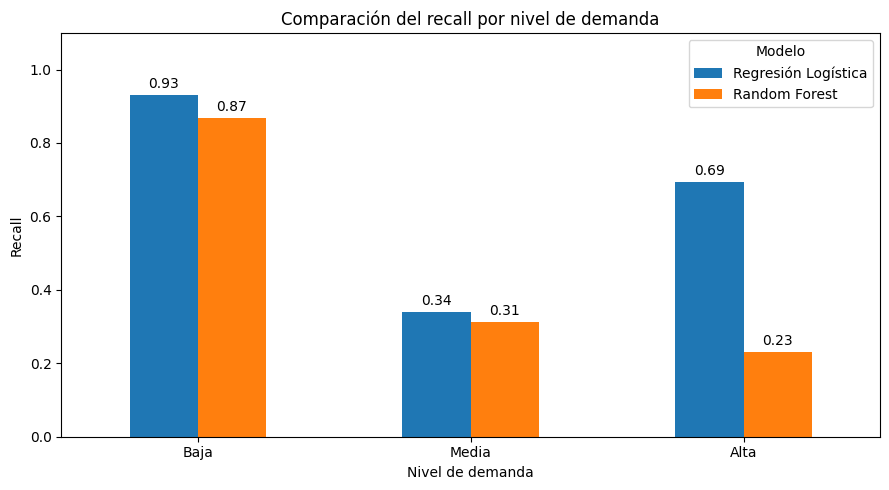

In [19]:
# Categorías de demanda
orden_niveles = ["Baja", "Media", "Alta"]

# Calcular recall por categoría para cada modelo
recall_logistica = recall_score(
    y_test,
    y_pred_logistica,
    labels=orden_niveles,
    average=None,
    zero_division=0
)

recall_rf = recall_score(
    y_test,
    y_pred_rf,
    labels=orden_niveles,
    average=None,
    zero_division=0
)

# Crear DataFrame para comparar los resultados
df_recall = pd.DataFrame({
    "Nivel de demanda": orden_niveles,
    "Regresión Logística": recall_logistica,
    "Random Forest": recall_rf
})

# Generar gráfico de barras
ax = df_recall.set_index("Nivel de demanda").plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Comparación del recall por nivel de demanda")
ax.set_xlabel("Nivel de demanda")
ax.set_ylabel("Recall")
ax.set_ylim(0, 1.1)

# Mostrar valores sobre las barras
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", padding=3)

plt.legend(title="Modelo")
plt.tight_layout()
plt.show()

**Interpretación del gráfico**

El gráfico permite observar que ambos modelos presentan un mejor desempeño en la identificación de la demanda Baja y mayores dificultades para clasificar la demanda Media.

En la categoría Alta se observa una diferencia importante: la Regresión Logística identifica aproximadamente el 69 % de los registros reales de demanda elevada, mientras que Random Forest identifica solamente el 23 %.

Estos resultados refuerzan la elección preliminar de la Regresión Logística como el modelo con mejor desempeño para los objetivos de la investigación, considerando las configuraciones evaluadas.

**Interpretación general de los resultados**

Los resultados obtenidos muestran que el modelo de **Regresión Logística presentó un mejor desempeño general** que Random Forest sobre el conjunto de prueba correspondiente al año 2021.

La Regresión Logística alcanzó una exactitud del **67,45 %** y un F1-score macro de **0,6277**, mientras que Random Forest obtuvo una exactitud del **56,84 %** y un F1-score macro de **0,4631**.

Al analizar los resultados por categoría, se observa que ambos modelos lograron identificar con mayor facilidad los registros de demanda Baja. En cambio, la categoría Media presentó mayores dificultades de clasificación, con valores de recall de 0,34 para Regresión Logística y 0,31 para Random Forest.

Una de las diferencias más relevantes se encuentra en la categoría **Alta**, donde la Regresión Logística alcanzó un recall de **0,69**, frente al **0,23** obtenido por Random Forest. Este resultado es especialmente importante para nuestra investigación, ya que buscamos identificar niveles elevados de demanda de pasajeros que podrían estar asociados con situaciones de congestión en la red de subtes.

La comparación permite observar que, con las configuraciones iniciales utilizadas, la Regresión Logística presenta una mejor capacidad predictiva sobre los registros de 2021. Sin embargo, los resultados también evidencian limitaciones, particularmente en la identificación de la demanda Media.

Estas diferencias deben interpretarse considerando que los patrones de movilidad pudieron haber cambiado durante el período analizado y que la distribución de los niveles de demanda en 2021 es diferente de la observada en los datos de entrenamiento.

En conclusión, **la Regresión Logística se presenta como el modelo más prometedor entre los dos evaluados hasta el momento**. No obstante, será necesario complementar el análisis mediante matrices de confusión para comprender mejor los errores de clasificación y evaluar posibles ajustes que permitan mejorar el desempeño de los modelos.

#### 7.4 Análisis mediante matrices de confusión

Para complementar la evaluación de los modelos, se utilizarán **matrices de confusión**, que permiten visualizar la distribución de las predicciones correctas e incorrectas para cada categoría de demanda.

Una matriz de confusión compara las categorías reales con las categorías predichas por el modelo:

- **Filas:** representan los niveles de demanda reales.
- **Columnas:** representan los niveles de demanda predichos.
- **Diagonal principal:** contiene los registros clasificados correctamente.
- **Valores fuera de la diagonal:** representan los errores de clasificación.

En esta investigación se construirán matrices de confusión para los modelos de Regresión Logística y Random Forest, considerando las categorías Baja, Media y Alta.

Este análisis permitirá identificar qué niveles de demanda presentan mayores dificultades de clasificación y determinar si los modelos tienden a confundir la demanda Alta con las categorías Media o Baja.

Dado que el objetivo del estudio incluye la identificación de situaciones de demanda elevada, se prestará especial atención a los registros de demanda Alta que no hayan sido reconocidos correctamente por los modelos.

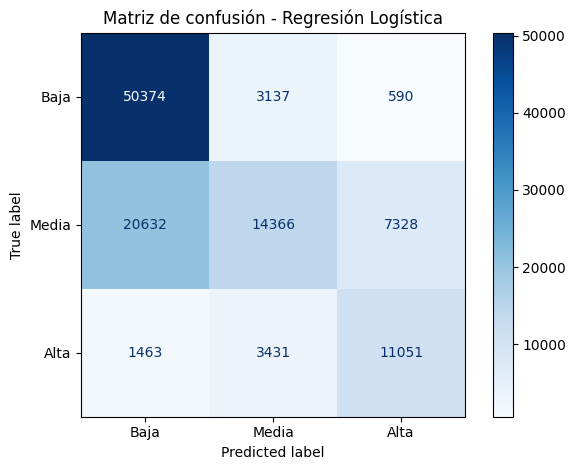

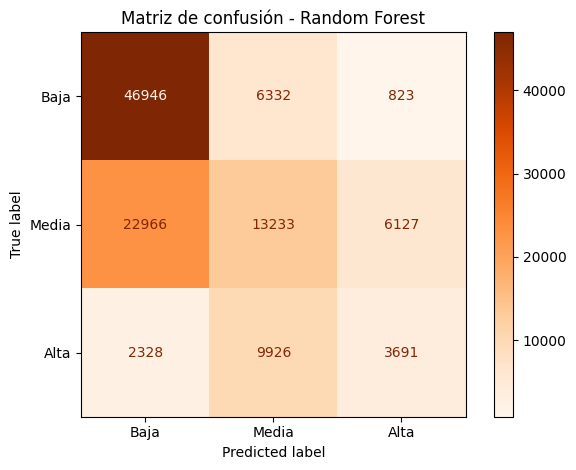

In [20]:

# Matrices de confusión de los modelos

orden_niveles = ["Baja", "Media", "Alta"]

# Calcular las matrices de confusión
matriz_logistica = confusion_matrix(
    y_test,
    y_pred_logistica,
    labels=orden_niveles
)

matriz_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=orden_niveles
)

# Visualizar la matriz de Regresión Logística
disp_logistica = ConfusionMatrixDisplay(
    confusion_matrix=matriz_logistica,
    display_labels=orden_niveles
)

disp_logistica.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Regresión Logística")
plt.tight_layout()
plt.show()

# Visualizar la matriz de Random Forest
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=orden_niveles
)

disp_rf.plot(cmap="Oranges", values_format="d")
plt.title("Matriz de confusión - Random Forest")
plt.tight_layout()
plt.show()

**Interpretación de las matrices de confusión**

El análisis de las matrices de confusión permite identificar los principales aciertos y errores de los modelos de Regresión Logística y Random Forest sobre los registros correspondientes a 2021.

En ambos modelos, la categoría **Baja** presenta la mayor cantidad de clasificaciones correctas. La Regresión Logística identificó correctamente 50.374 registros, mientras que Random Forest identificó 46.946.

La categoría **Media** presenta dificultades importantes en ambos algoritmos. En particular, se observa una tendencia a clasificar registros de demanda Media como Baja, con 20.632 casos en Regresión Logística y 22.966 en Random Forest.

Las diferencias más relevantes se observan en la categoría **Alta**. La Regresión Logística identificó correctamente 11.051 de los 15.945 registros reales, mientras que Random Forest reconoció solamente 3.691. En este último modelo, una parte considerable de los registros de demanda Alta fue clasificada incorrectamente como Media.

Estos resultados confirman que la Regresión Logística presenta una mayor capacidad para identificar niveles elevados de demanda con las configuraciones evaluadas, lo que resulta especialmente relevante para los objetivos de la investigación.

Sin embargo, ambos modelos muestran limitaciones, particularmente en la diferenciación de la demanda Media respecto de las categorías restantes.

En consecuencia, las matrices de confusión complementan las métricas obtenidas anteriormente y permiten comprender con mayor detalle los errores de clasificación, proporcionando información útil para evaluar posibles mejoras en los modelos.

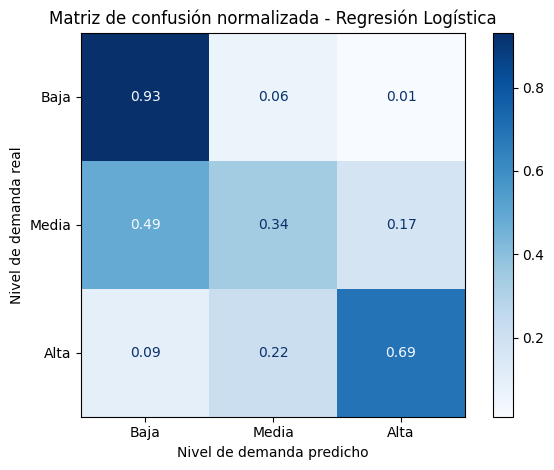

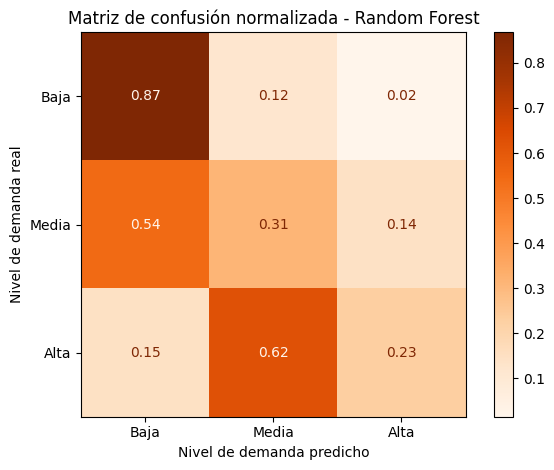

In [21]:
# Matrices de confusión normalizadas por categoría real

for nombre, predicciones, colores in [
    ("Regresión Logística", y_pred_logistica, "Blues"),
    ("Random Forest", y_pred_rf, "Oranges")
]:
    matriz_normalizada = confusion_matrix(
        y_test,
        predicciones,
        labels=orden_niveles,
        normalize="true"
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=matriz_normalizada,
        display_labels=orden_niveles
    )

    disp.plot(cmap=colores, values_format=".2f")
    plt.title(f"Matriz de confusión normalizada - {nombre}")
    plt.xlabel("Nivel de demanda predicho")
    plt.ylabel("Nivel de demanda real")
    plt.tight_layout()
    plt.show()

**Interpretación de las matrices de confusión normalizadas**

Las matrices de confusión normalizadas permiten analizar la proporción de predicciones correctas e incorrectas para cada nivel de demanda, independientemente de la cantidad de registros que contiene cada categoría.

Los resultados muestran que ambos modelos presentan un mejor desempeño en la clasificación de la demanda Baja, con un 93 % de aciertos para Regresión Logística y un 87 % para Random Forest.

En la categoría Media se observan dificultades importantes, ya que ambos algoritmos tienden a clasificar una proporción considerable de estos registros como demanda Baja. Esta situación se presenta en aproximadamente el 49 % de los casos para Regresión Logística y el 54 % para Random Forest.

La principal diferencia aparece en la categoría Alta. Mientras que Regresión Logística identifica correctamente el 69 % de los registros, Random Forest reconoce solamente el 23 % y clasifica aproximadamente el 62 % como demanda Media.

En conjunto, estos resultados refuerzan lo observado en las métricas de clasificación y muestran que **Regresión Logística presenta un mejor desempeño para identificar niveles elevados de demanda**.

Sin embargo, ambos modelos evidencian dificultades para diferenciar correctamente la demanda Media, lo que representa una limitación que deberá considerarse al interpretar los resultados de la investigación.

###8. Análisis complementario con clustering.

xxxx

###9. Interpretación y conclusiones.